In [8]:
#carga de datos
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

df = pd.read_csv("../data/sentiment_data.csv")
print(df.shape)
df.head()

(241145, 3)


,Unnamed: 0,Comment,Sentiment
0,0,lets forget apple pay required brand new iphon...,1
1,1,nz retailers don’t even contactless credit car...,0
2,2,forever acknowledge channel help lessons ideas...,2
3,3,whenever go place doesn’t take apple pay doesn...,0
4,4,apple pay convenient secure easy use used kore...,2


In [9]:
df = df.drop(columns=["Unnamed: 0"])   #indice sobrante
print(df.isna().sum())
print(df["Sentiment"].value_counts())

Comment      217
Sentiment      0
dtype: int64
Sentiment
2    103059
1     82972
0     55114
Name: count, dtype: int64


In [10]:
#limpieza de datos
n0 = len(df)

#datos nulos
df = df.dropna(subset=["Comment"])

#apostrofes curvos -> rectos, y espacios sobrantes
df["Comment"] = (df["Comment"].str.replace("’", "'", regex=False).str.replace("‘", "'", regex=False).str.strip())

#datos con textos muy cortos (menos de 3 palabras)
df["n_palabras"] = df["Comment"].str.split().str.len()
df = df[df["n_palabras"] >= 3] #se eliminan porque aportan poco contexto

print(f"Filas: {n0} -> {len(df)}")

Filas: 241145 -> 230799


In [4]:
#datos duplicados

#textos con etiquetas distintas: no sabemos cuál es la correcta
n_etiquetas = df.groupby("Comment")["Sentiment"].nunique()
conflictivos = n_etiquetas[n_etiquetas > 1].index
print("Textos con etiquetas contradictorias:", len(conflictivos))
df = df[~df["Comment"].isin(conflictivos)]

#duplicados exactos
print("Duplicados:", df.duplicated("Comment").sum())
df = df.drop_duplicates("Comment")

print(df.shape)

Textos con etiquetas contradictorias: 31
Duplicados: 22190
(208446, 3)


label
positivo    100560
neutral      76745
negativo     53494
Name: count, dtype: int64


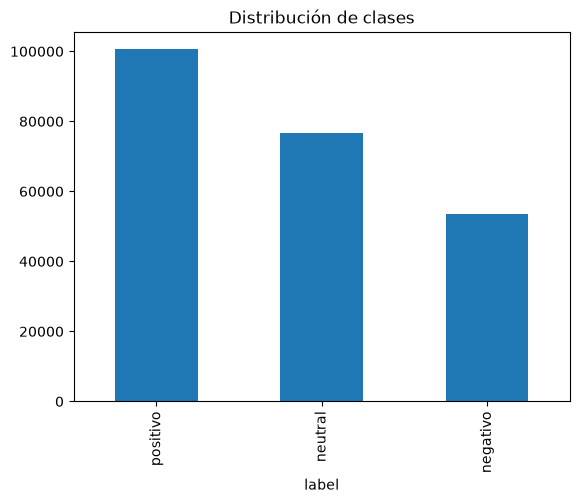

In [11]:
#etiquetas

nombres = {0: "negativo", 1: "neutral", 2: "positivo"}
df["label"] = df["Sentiment"].map(nombres)

print(df["label"].value_counts())
df["label"].value_counts().plot(kind="bar", title="Distribución de clases")
plt.show()

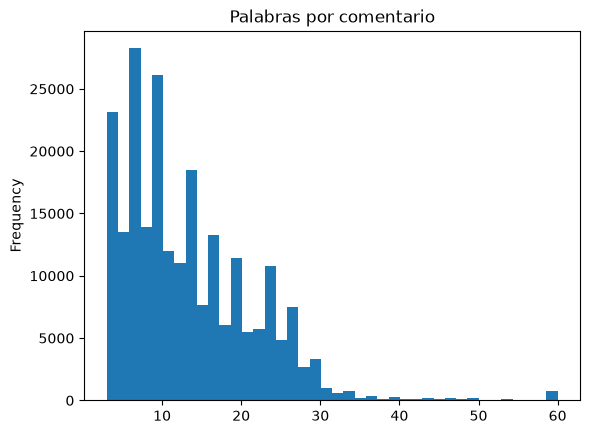

In [12]:
#longitud de texto

df["n_palabras"].describe()

df["n_palabras"].clip(upper=60).plot(kind="hist", bins=40, title="Palabras por comentario")
plt.show()


In [15]:
#separar y guardar

df = df[["Comment", "Sentiment", "label"]]

train, test = train_test_split(
    df, test_size=0.2, random_state=42, stratify=df["Sentiment"]
)
print(len(train), len(test))

train.to_csv("../data/train.csv", index=False)
test.to_csv("../data/test.csv", index=False)


184639 46160
